# 09 — Trend figures on the directly predicted GGI

The trend analysis from [`src/technical_report/trend.qmd`](../technical_report/trend.qmd), ported to
Python. **The measure is the directly predicted gender gap index** — the `{ind}_fm_ratio` outcome of
the published national models, read straight from the golden series — which is the measure the
`.qmd` plots and the measure behind every published trend figure to date.

This is the counterpart to `04_coherent_ggi_figures.ipynb`, which runs the same figure set on the
*coherent* GGI derived from the predicted female and male levels. The two notebooks answer the same
question on two different measures, and for the case-study countries the answer differs: on the
direct measure Turkmenistan's gap **widens** across the window, on the coherent measure it narrows
(see 04's notes and D43). Keeping both is the point — 05 is where they are compared.

Because the measure here is the one the `.qmd` used, two things it did that 04 had to drop come
back:

1. **Uncertainty ribbons.** `predicted_error` is published alongside `predicted` for
   `{ind}_fm_ratio`, so `pred ± predicted_error` is a band the series actually carries. It has no
   coherent counterpart — a ratio's variance is not the ratio of variances — which is why 04 omits it.
2. **The event annotations.** Social-media shutdown, regime change, intensified internet control.
   Their coordinates were hand-tuned to this measure's scale, so here they land where they were
   meant to.

### What changed from the `.qmd`

- **The window is derived, not hardcoded, and ends at the last complete year.** The `.qmd` wrote
  `pred[year == 2025] - pred[year == 2015]`; here `TREND_END` is read off the month counts, so the
  window extends itself as each year completes. The year still in progress is **dropped**: it
  averages fewer months than a full year, and it is the endpoint every trend and every threshold is
  read off (D48, D54).
- **Yemen is excluded upstream, not per figure.** The `.qmd` wrote `gid_0 != "YEM"` into two of the
  eight GGI figures it saves — the two stagnant ones — and left it out of the other six, the paper
  figure included. It comes out of `params.excluded_countries` here, once, for every figure (D21).
- **Colour follows the project palette.** The `.qmd` picked ad-hoc hexes (`#FF6F61`, `#C77CFF`, …)
  that fail the colour-vision checks in D23. Figures with more than eight countries highlight the
  largest movers and draw the rest in recessive grey instead of cycling a six-colour palette five
  times, which is 04's treatment for the same problem.
- **The Turkmenistan Facebook panel plotted Turkey.** `trend.qmd:517` filters `iso3 == "TUR"` under
  the title *"FB indicator changes for Turkmenistan"*. TKM is Turkmenistan; TUR is Türkiye. Fixed in
  §7, with both drawn so the substitution is visible.
- **The World Bank income classification is dropped.** The `.qmd` joined it and then never used it
  in any figure, and the workbook is not in `data/`.

### What this replaces

This notebook was `09_post_analysis_trend.ipynb`, a random-forest re-prediction exercise whose
model pickles no longer exist and whose later cells had never run. The random-forest line was
retired in 2026-08 (D13) and its notebooks archived in 2026-08-31 (D51); that one is
[`src/archive/post_analysis_trend_superseded.ipynb`](../archive/post_analysis_trend_superseded.ipynb).
Its two salvageable pieces — the national-vs-subnational comparison and the survey-source tallies —
are §8 and §9 below, rebuilt on the published predictions. The name changed with the content: this
is the direct-GGI counterpart to `04`, not a post-hoc check on a refit.

In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import params
import plotting as plot
import utils

NOTEBOOK = '09_direct_ggi_trend_figures'
INDICATORS = params.COHERENT_GGI['indicators']
TREND_START = 2015

# copy the dict first, so turning saving on here does not mutate params.STYLE for every other
# importer in the process
plot.STYLE = dict(plot.STYLE); plot.STYLE['save'] = True
STYLE, PALETTE = plot.STYLE, plot.PALETTE
INK, MUTED, GRID, FLAG = plot.INK, plot.MUTED, plot.GRID, plot.FLAG

STAMP = pd.Timestamp.today().strftime('%Y%m%d')
print('figures ->', params.fig_dir(NOTEBOOK).relative_to(params.ROOT))
print('tables  ->', params.table_dir(NOTEBOOK).relative_to(params.ROOT))

figures -> outputs/fig/09_direct_ggi_trend_figures
tables  -> outputs/tables/09_direct_ggi_trend_figures


## 0. The annual panel

`trend.qmd` reads `aggregate_files.csv` — the published country-month predictions — and averages
the months into a calendar year. That file is the same golden series `04` and `05` build the
coherent GGI from (`params.COHERENT_GGI['source']`), read here in its published long form so the
`{ind}_fm_ratio` outcome and its `predicted_error` arrive together.

The derived measures keep the `.qmd`'s definitions:

| | |
| --- | --- |
| `total_gain` | `pred[TREND_END] - pred[TREND_START]` |
| `annual_change` | year-on-year first difference |
| `mean_pred` | mean over the window |
| `proportional_gain` | `total_gain / pred[TREND_START]` |

`TREND_END` is the last **complete** calendar year, not the last year in the file. Everything that
classifies a country — closing, widening, stagnant, best, worst — is measured to it.

In [2]:
long = pd.read_csv(params.COHERENT_GGI['source'])
long = long.drop(columns=[c for c in long.columns if c.startswith('Unnamed')])
long['year'] = long['date'].str.slice(0, 4).astype(int)
long['month'] = long['date'].str.slice(5, 7).astype(int)

# Yemen's level predictions are degenerate — female internet sits on the zero floor throughout, so
# every ratio derived from it is meaningless. The .qmd dropped it in two of its eight GGI figures
# and not in the rest; it comes out once here (params.excluded_countries, D21).
excluded = long['gid_0'].isin(params.excluded_countries)
print(f'excluding {sorted(long.loc[excluded, "gid_0"].unique())}: {int(excluded.sum())} rows')
long = long[~excluded].copy()

# Pre-2019 the pipeline published one figure per year; from 2019 it is monthly, so a recent year
# with fewer than twelve months is still filling up.
months_per_year = long.groupby('year')['month'].nunique()
# The window ends at the last COMPLETE calendar year (D18, D54). From 2019 the pipeline publishes
# monthly, so a year still in progress averages fewer months than a full one — and it is the
# endpoint every figure and every threshold here reads, so a short year biases exactly the quantity
# being reported. The partial year is dropped rather than plotted and starred: a point on a trend
# line is read as a trend whatever the footnote next to it says. TREND_END moves on its own as the
# twelfth month of a year lands.
complete = months_per_year[(months_per_year.index < 2019) | (months_per_year == 12)]
TREND_END = int(complete.index.max())
DROPPED = [int(y) for y in months_per_year.index if y > TREND_END]

annual = (long.groupby(['gid_0', 'outcome', 'year'], as_index=False)
              .agg(pred=('predicted', 'mean'), predicted_error=('predicted_error', 'mean'),
                   n_months=('month', 'nunique')))
annual = annual[annual['year'].between(TREND_START, TREND_END)].copy()

annual['country'] = [utils.get_country_name_from_iso3(x) for x in annual['gid_0']]
annual = annual.merge(utils.load_regions(), left_on='gid_0', right_on='iso3',
                      how='left').drop(columns='iso3')

# region2: World Bank region, with Sub-Saharan Africa split into subregions (from the .qmd, now in
# params so 04 and 09 cannot drift apart)
iso_to_sub = {iso: sub for sub, isos in params.ssa_subregions.items() for iso in isos}
annual['subregion'] = annual['gid_0'].map(iso_to_sub).fillna('Other')
annual['region2'] = np.where(annual['region'] == 'Sub-Saharan Africa',
                             annual['subregion'], annual['region'])

annual = annual.sort_values(['gid_0', 'outcome', 'year'])
annual['annual_change'] = annual.groupby(['gid_0', 'outcome'])['pred'].diff()

dropped = ('  |  dropped as partial: '
           + ', '.join(f'{y} ({int(months_per_year.loc[y])} months)' for y in DROPPED)) if DROPPED else ''
print(f'window {TREND_START}-{TREND_END}{dropped}'
      f'  |  thresholds measured {TREND_START} -> {TREND_END}')
print(f"{annual['gid_0'].nunique()} countries, {sorted(annual['outcome'].unique())}")
annual.head()

excluding ['YEM']: 522 rows


window 2015-2026  (2026 is partial: 6 months)  |  thresholds measured 2015 -> 2025
213 countries, ['internet_fm_ratio', 'internet_men', 'internet_women', 'mobile_fm_ratio', 'mobile_men', 'mobile_women']


,gid_0,outcome,year,pred,predicted_error,n_months,country,region,subregion,region2,annual_change
0,ABW,internet_fm_ratio,2015,0.935000,0.083,1,Aruba,Latin America & Caribbean,Other,Latin America & Caribbean,NaN
1,ABW,internet_fm_ratio,2016,0.947000,0.083,1,Aruba,Latin America & Caribbean,Other,Latin America & Caribbean,0.012000
2,ABW,internet_fm_ratio,2017,0.956000,0.083,1,Aruba,Latin America & Caribbean,Other,Latin America & Caribbean,0.009000
3,ABW,internet_fm_ratio,2018,0.968000,0.083,1,Aruba,Latin America & Caribbean,Other,Latin America & Caribbean,0.012000
4,ABW,internet_fm_ratio,2019,0.974333,0.083,12,Aruba,Latin America & Caribbean,Other,Latin America & Caribbean,0.006333


In [3]:
def country_panel(outcome):
    """
    country x year matrices of the prediction and its error, plus the summaries the filters use

    One function for both indicators and every figure below, so a threshold can only ever be
    computed one way.
    """
    frame = annual[annual['outcome'] == outcome]
    wide = frame.pivot_table(index='gid_0', columns='year', values='pred')
    err = frame.pivot_table(index='gid_0', columns='year', values='predicted_error')

    summary = pd.DataFrame({
        'total_gain': wide[TREND_END] - wide[TREND_START],
        'mean_pred': wide.loc[:, TREND_START:TREND_END].mean(axis=1),
    })
    summary['proportional_gain'] = summary['total_gain'] / wide[TREND_START]
    names = frame.drop_duplicates('gid_0').set_index('gid_0')
    summary['country'] = names['country']
    summary['region'] = names['region']
    summary['region2'] = names['region2']
    return wide, err, summary


panels = {f'{ind}_fm_ratio': country_panel(f'{ind}_fm_ratio') for ind in INDICATORS}
wide_i, err_i, sum_i = panels['internet_fm_ratio']
wide_m, err_m, sum_m = panels['mobile_fm_ratio']

summaries = pd.concat([s.assign(outcome=o) for o, (_, _, s) in panels.items()])
summaries.to_csv(params.table_dir(NOTEBOOK) / f'trend_country_summary_{STAMP}.csv')
print(f'{len(sum_i)} internet countries, {len(sum_m)} mobile countries '
      f'-> trend_country_summary_{STAMP}.csv')
summaries.groupby('outcome')[['total_gain', 'mean_pred', 'proportional_gain']].describe().T.round(3)

213 internet countries, 213 mobile countries -> trend_country_summary_20260831.csv


outcome                  internet_fm_ratio  mobile_fm_ratio
total_gain        count            213.000          213.000
                  mean               0.112            0.046
                  std                0.086            0.057
                  min               -0.081           -0.066
                  25%                0.057            0.000
                  50%                0.090            0.023
                  75%                0.153            0.081
                  max                0.422            0.250
mean_pred         count            213.000          213.000
                  mean               0.857            0.934
                  std                0.177            0.103
                  min                0.196            0.514
                  25%                0.798            0.907
                  50%                0.946            0.991
                  75%                0.979            1.000
                  max                1.000            1.000
proportional_gain count            213.000          213.000
                  mean               0.201            0.060
                  std                0.276            0.083
                  min               -0.107           -0.066
                  25%                0.063            0.000
                  50%                0.103            0.024
                  75%                0.220            0.094
                  max                2.304            0.390

### The figure helper

One function draws every trend figure below. Ribbons and a palette colour go to the countries the
figure is about; anything past the eighth series is drawn in recessive grey, because cycling eight
hues across forty countries makes colour mean nothing (D23). Identity is carried by a direct label
at the end of the line rather than by a legend, so no reader has to match a hue to a key.

In [4]:
def spread_labels(ends, min_gap):
    """
    push end-of-line labels apart so none overprints its neighbour

    Walks the end points bottom-up, lifting any that sits closer than `min_gap` to the one below,
    then recentres so the block stays near its original position.
    """
    ordered = sorted(ends, key=lambda k: ends[k][0])
    placed, previous = {}, -np.inf
    for iso in ordered:
        y = max(ends[iso][0], previous + min_gap)
        placed[iso] = y
        previous = y
    shift = np.mean([ends[i][0] for i in ordered]) - np.mean(list(placed.values()))
    return {iso: y + shift for iso, y in placed.items()}


def trend_lines(ax, wide, err, summary, countries, colours=None, ribbon=True, label=True,
                highlight=8, years=None):
    """
    the .qmd's `geom_line + geom_point + geom_ribbon` per country, in the project's treatment

    Args:
        wide, err, summary: as returned by `country_panel`.
        countries: iso3 codes to draw, in any order — they are ranked by |total_gain| so the
            largest movers get the colours.
        colours: optional {iso3: hex} to pin identity across panels (the paper figure needs this);
            otherwise the palette is assigned in `params.plot_color_order`.
        ribbon: draw `pred ± predicted_error`. Off when the bands would overlap into mud.
        highlight: how many countries get a colour; the rest are grey context.

    Returns the isos that were coloured, so a caller can report the split.
    """
    years = years if years is not None else list(wide.columns)
    countries = [c for c in countries if c in wide.index]
    if not countries:
        print('  [skip] no countries meet the criteria')
        return []

    ranked = summary.loc[countries, 'total_gain'].abs().sort_values(ascending=False)
    focus = list(ranked.index[:highlight])
    context = [c for c in countries if c not in focus]

    for iso in context:
        ax.plot(years, wide.loc[iso, years], color=GRID, linewidth=1, zorder=1)

    ends = {}
    for i, iso in enumerate(focus):
        colour = (colours or {}).get(iso, PALETTE[i % len(PALETTE)])
        series = wide.loc[iso, years]
        if ribbon:
            band = err.loc[iso, years]
            ax.fill_between(years, series - band, series + band, color=colour, alpha=0.2,
                            linewidth=0, zorder=2)
        ax.plot(years, series, color=colour, linewidth=1.6, zorder=3)
        ax.plot(years, series, 'o', color=colour, markersize=4, zorder=4)
        ends[iso] = (series.iloc[-1], colour)

    if label:
        span = np.nanmax(wide.loc[countries, years].values) - np.nanmin(wide.loc[countries, years].values)
        for iso, y_label in spread_labels(ends, min_gap=max(span, 0.1) * 0.05).items():
            y_true, colour = ends[iso]
            if abs(y_label - y_true) > 1e-9:
                ax.plot([years[-1], years[-1] + 0.3], [y_true, y_label], color=colour,
                        linewidth=0.8, alpha=0.6, zorder=2)
            ax.annotate(f'  {summary.loc[iso, "country"]}', (years[-1] + 0.3, y_label),
                        color=INK, fontsize=STYLE['tick_fs'], va='center', zorder=5)

    if context:
        ax.plot([], [], color=GRID, linewidth=1,
                label=f'{len(context)} further countr{"y" if len(context) == 1 else "ies"}')
        ax.legend(frameon=False, fontsize=STYLE['tick_fs'], loc='lower right', labelcolor=MUTED)
    return focus


def year_axis(ax, years, gutter=0.0, step=1):
    """x ticks on data years only — every year in the window is complete (D54)"""
    ticks = list(range(years[0], years[-1] + 1, step))
    if years[-1] not in ticks:
        ticks.append(years[-1])
    ax.set_xlim(years[0] - 0.15, years[-1] + gutter)
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(y) for y in ticks])
    return ax


YEARS = list(wide_i.columns)   # complete years only, so this is also the published window
print(f'window {YEARS[0]}-{YEARS[-1]}  ({len(YEARS)} complete years)')

full window 2015-2026  ·  published window 2015-2025


## 1. Internet — closing gender gaps

`total_gain >= 0.3`, the `.qmd`'s threshold, now measured to the last complete year.

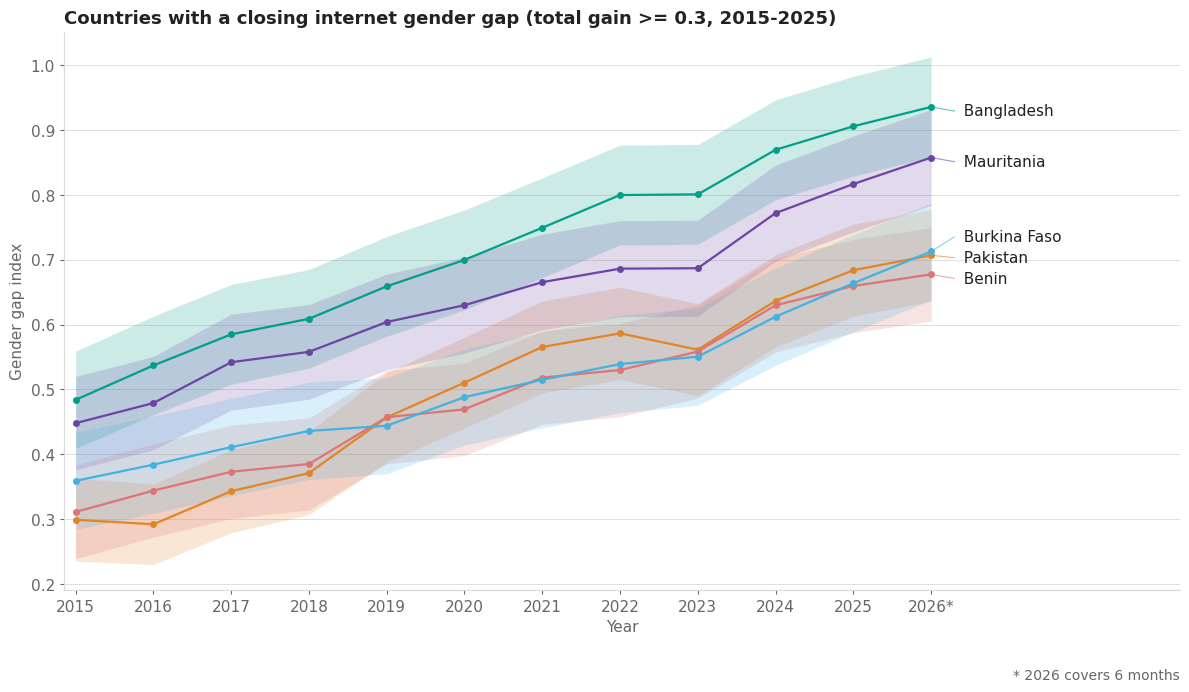

5 countries, 5 labelled


,country,region2,total_gain,mean_pred
gid_0,,,,
BGD,Bangladesh,South Asia,0.422,0.700
PAK,Pakistan,South Asia,0.385,0.482
MRT,Mauritania,Western Africa,0.369,0.626
BEN,Benin,Western Africa,0.349,0.476
BFA,Burkina Faso,Western Africa,0.305,0.491


In [5]:
closing_i = sum_i.index[sum_i['total_gain'] >= 0.3].tolist()

fig, ax = plt.subplots(figsize=plot.figsize('full'))
focus = trend_lines(ax, wide_i, err_i, sum_i, closing_i, ribbon=len(closing_i) <= 8)
plot.tidy(ax, title=f'Countries with a closing internet gender gap (total gain >= 0.3, '
                    f'{TREND_START}-{TREND_END})',
          xlabel='Year', ylabel='Gender gap index', grid='y')
year_axis(ax, YEARS, gutter=3.2)
fig.tight_layout()
plot.save(fig, NOTEBOOK, '01_internet_closing')
plt.show()

print(f'{len(closing_i)} countries, {len(focus)} labelled')
sum_i.loc[closing_i, ['country', 'region2', 'total_gain', 'mean_pred']].sort_values(
    'total_gain', ascending=False).round(3).head(12)

## 2. Internet — the widening case studies

Afghanistan, Eritrea, Djibouti, Turkmenistan, with the `.qmd`'s event annotations. The arrow and
label coordinates are the ones from `trend.qmd:377-424`, unchanged: they were tuned to this measure
on this window, so they land on the right part of the line.

The annotations mark *when a documented event happened*, not a tested effect. Nothing here
identifies the event's contribution to the series — the models carry no country-specific term, so a
country's predicted path moves only when its Facebook and development covariates move. Read the
labels as context for the shape, not as a cause of it.

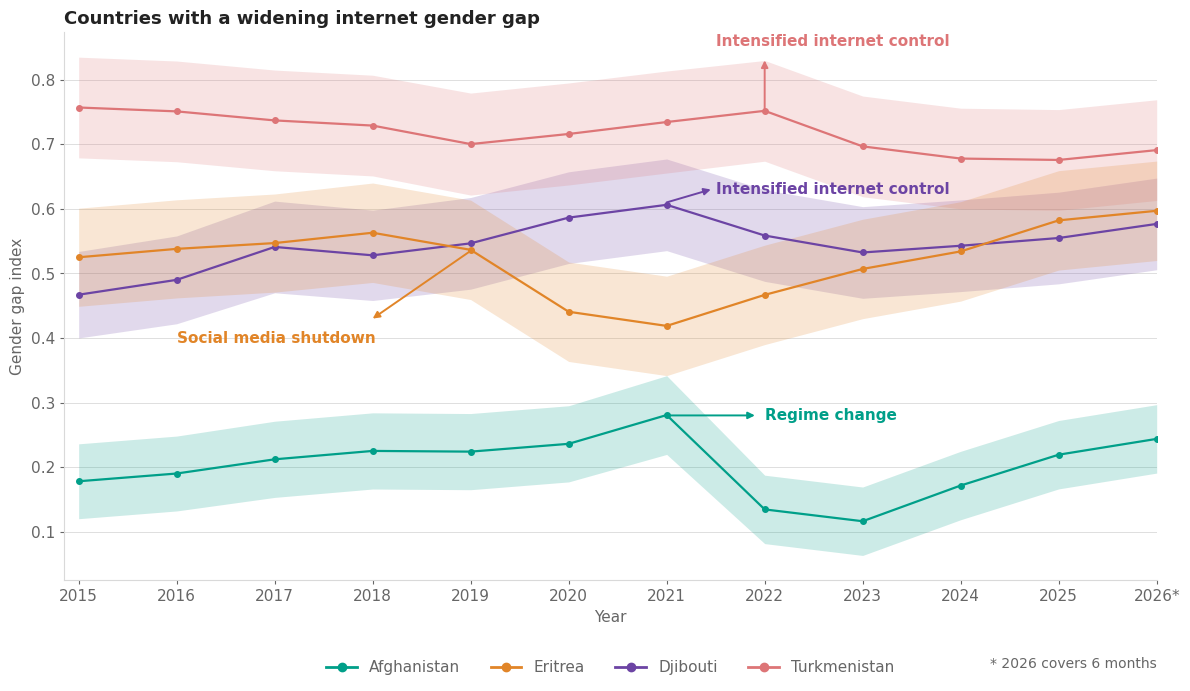

,country,total_gain,mean_pred
gid_0,,,
AFG,Afghanistan,0.041,0.199
ERI,Eritrea,0.057,0.514
DJI,Djibouti,0.088,0.541
TKM,Turkmenistan,-0.081,0.721


In [6]:
CASE_STUDIES = ['AFG', 'ERI', 'DJI', 'TKM']

# Identity colours, pinned so a country keeps its hue across every panel in this notebook. Assigned
# in params.plot_color_order rather than the .qmd's ad-hoc hexes, which fail the D52 checks.
case_colours = dict(zip(CASE_STUDIES, PALETTE))
best_worst_colours = {}   # filled in §5

# (label, arrow tail, arrow head, text anchor) — the .qmd's coordinates, in data units
EVENTS = [
    ('ERI', 'Social media shutdown',      (2019, 0.535), (2018, 0.43),   (2016.0, 0.40)),
    ('AFG', 'Regime change',              (2021, 0.28),  (2021.9, 0.28), (2022.0, 0.28)),
    ('TKM', 'Intensified internet control', (2022, 0.75), (2022, 0.83),  (2021.5, 0.86)),
    ('DJI', 'Intensified internet control', (2021, 0.61), (2021.45, 0.63), (2021.5, 0.63)),
]


def annotate_events(ax, colours):
    """the .qmd's hand-placed arrows and labels, drawn in each country's own colour"""
    for iso, text, tail, head, anchor in EVENTS:
        colour = colours[iso]
        ax.annotate('', xy=head, xytext=tail, zorder=6,
                    arrowprops=dict(arrowstyle='-|>', color=colour, linewidth=1.4,
                                    shrinkA=0, shrinkB=0))
        ax.annotate(text, anchor, color=colour, fontsize=STYLE['tick_fs'], fontweight='bold',
                    ha='left', va='center', zorder=6)


fig, ax = plt.subplots(figsize=plot.figsize('full'))
trend_lines(ax, wide_i, err_i, sum_i, CASE_STUDIES, colours=case_colours, label=False)
annotate_events(ax, case_colours)
plot.tidy(ax, title='Countries with a widening internet gender gap',
          xlabel='Year', ylabel='Gender gap index', grid='y')
year_axis(ax, YEARS)
ax.legend(handles=[plt.Line2D([], [], color=case_colours[c], linewidth=2, marker='o',
                              label=sum_i.loc[c, 'country']) for c in CASE_STUDIES],
          frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED,
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4)
fig.tight_layout()
plot.save(fig, NOTEBOOK, '02_internet_widening_case_studies')
plt.show()

sum_i.loc[CASE_STUDIES, ['country', 'total_gain', 'mean_pred']].round(3)

## 3. Internet — proportionally large gains, by region

`proportional_gain > 0.25`: a gain worth a quarter of the country's own 2015 level, which selects
countries that started low and moved, rather than countries that were already near parity. The
black line is the **mean across the countries shown in that panel** — the `.qmd`'s baseline, and it
is a mean of the selected countries, not of the region as a whole.

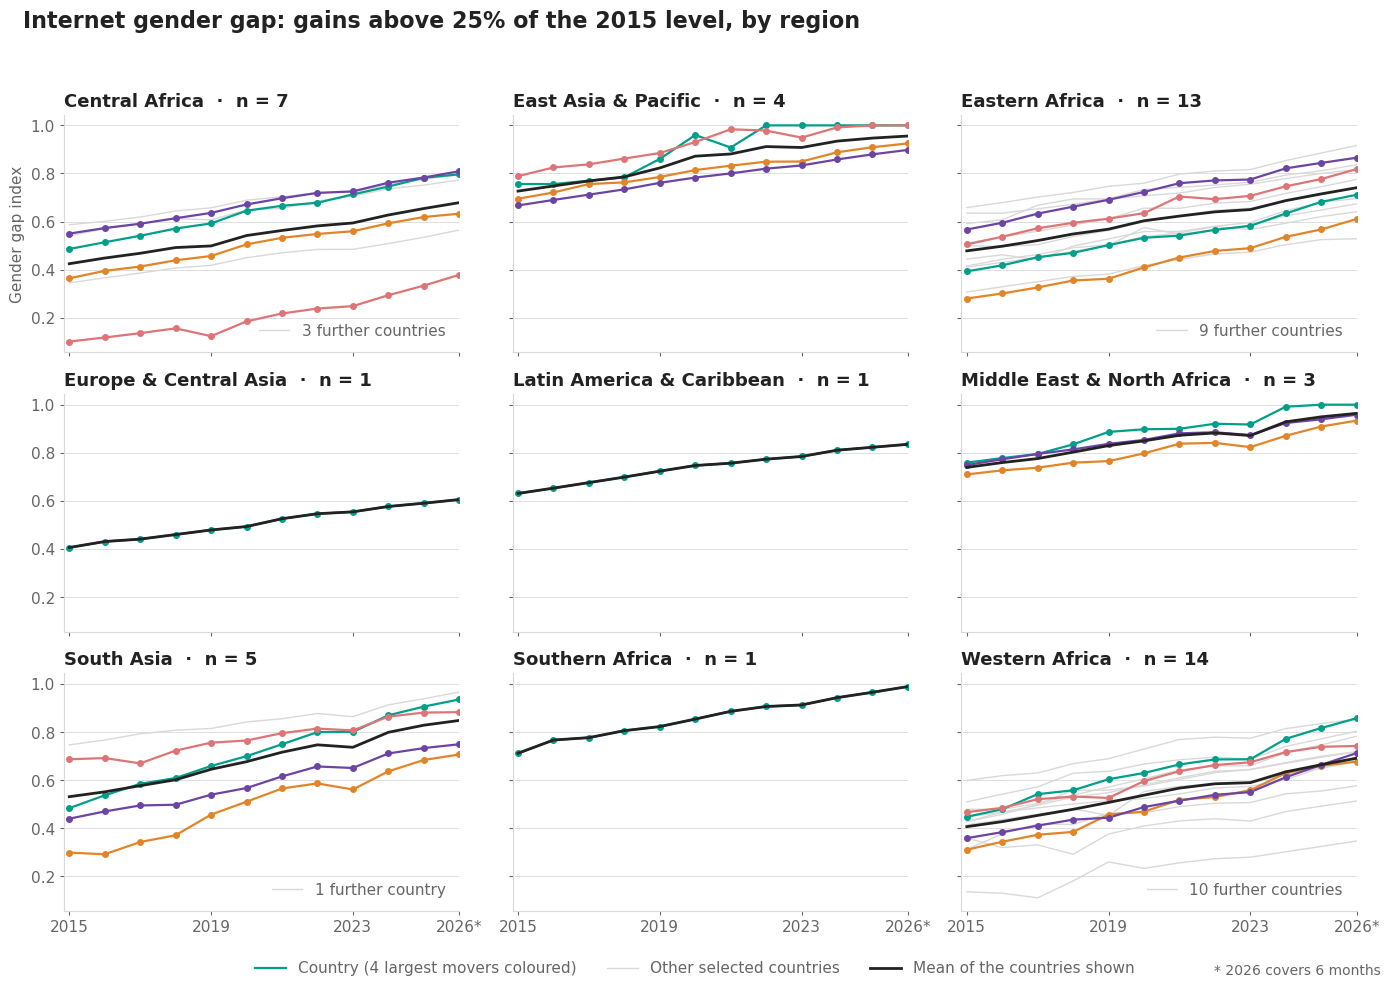

49 countries across 9 regions


In [7]:
selected = sum_i.index[sum_i['proportional_gain'] > 0.25].tolist()
by_region = sum_i.loc[selected].groupby('region2').groups
regions = [r for r in sorted(by_region) if len(by_region[r]) > 0]

ncol = 3
nrow = int(np.ceil(len(regions) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=plot.figsize('full', nrow=nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, region in zip(axes, regions):
    isos = list(by_region[region])
    trend_lines(ax, wide_i, err_i, sum_i, isos, ribbon=False, label=False, highlight=4)
    ax.plot(YEARS, wide_i.loc[isos, YEARS].mean(), color=INK, linewidth=2, linestyle='-', zorder=5)
    plot.tidy(ax, title=f'{region}  ·  n = {len(isos)}', grid='y')

for ax in axes[len(regions):]:
    ax.axis('off')
axes[0].set_ylabel('Gender gap index', fontsize=STYLE['tick_fs'], color=MUTED)
for ax in axes[:len(regions)]:
    year_axis(ax, YEARS, step=4)
handles = [plt.Line2D([], [], color=PALETTE[0], linewidth=1.6, label='Country (4 largest movers coloured)'),
           plt.Line2D([], [], color=GRID, linewidth=1, label='Other selected countries'),
           plt.Line2D([], [], color=INK, linewidth=2, label='Mean of the countries shown')]
plot.legend(fig, handles, y=-0.01)
plot.suptitle(fig, f'Internet gender gap: gains above 25% of the {TREND_START} level, by region')
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
plot.save(fig, NOTEBOOK, '03_internet_proportional_gain_by_region')
plt.show()

print(f'{len(selected)} countries across {len(regions)} regions')

## 4. Internet — large and stagnant gaps

`total_gain <= 0.1` **and** `mean_pred < 0.8`: the gap barely moved, and it was wide to begin with.
Both conditions matter — without the second, every country already sitting at parity qualifies for
having gone nowhere.

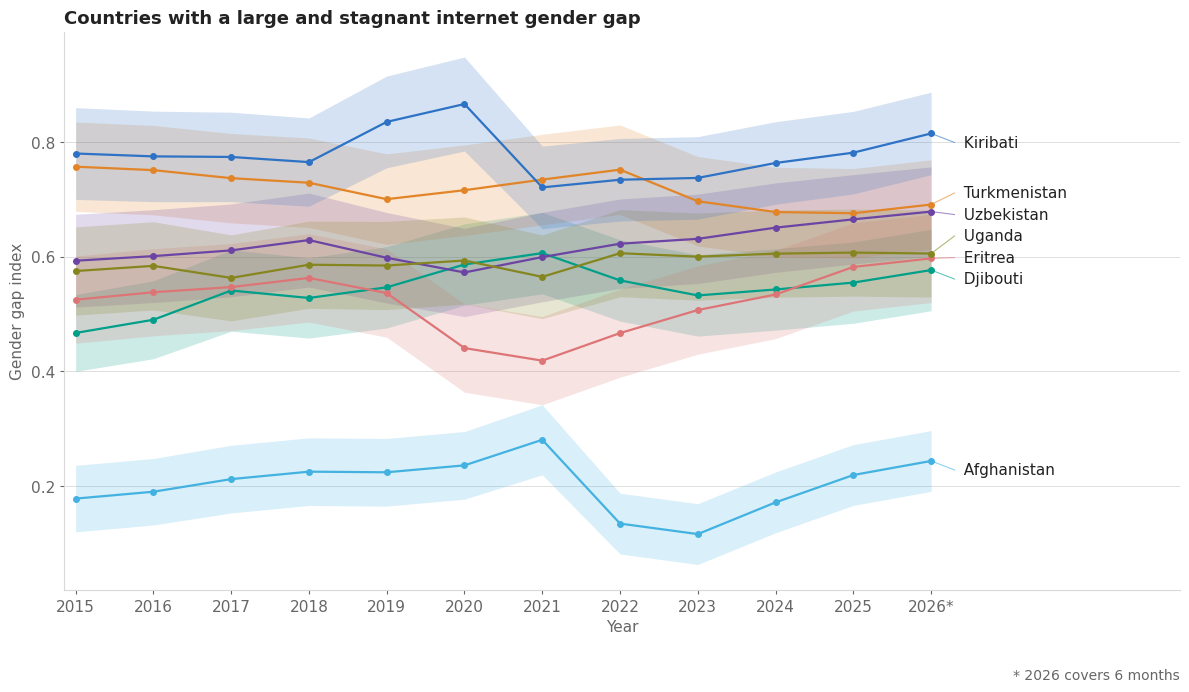

7 countries, 7 labelled


,country,region2,total_gain,mean_pred
gid_0,,,,
AFG,Afghanistan,South Asia,0.041,0.199
ERI,Eritrea,Eastern Africa,0.057,0.514
DJI,Djibouti,Middle East & North Africa,0.088,0.541
UGA,Uganda,Eastern Africa,0.032,0.588
UZB,Uzbekistan,Europe & Central Asia,0.072,0.616
TKM,Turkmenistan,Europe & Central Asia,-0.081,0.721
KIR,Kiribati,East Asia & Pacific,0.001,0.776


In [8]:
def stagnant(summary):
    keep = (summary['total_gain'] <= 0.1) & (summary['mean_pred'] < 0.8)
    return list(summary.index[keep])


stagnant_i = stagnant(sum_i)

fig, ax = plt.subplots(figsize=plot.figsize('full'))
focus = trend_lines(ax, wide_i, err_i, sum_i, stagnant_i, ribbon=len(stagnant_i) <= 8)
plot.tidy(ax, title='Countries with a large and stagnant internet gender gap',
          xlabel='Year', ylabel='Gender gap index', grid='y')
year_axis(ax, YEARS, gutter=3.2)
fig.tight_layout()
plot.save(fig, NOTEBOOK, '04_internet_stagnant')
plt.show()

print(f'{len(stagnant_i)} countries, {len(focus)} labelled')
sum_i.loc[stagnant_i, ['country', 'region2', 'total_gain', 'mean_pred']].sort_values(
    'mean_pred').round(3)

## 5. The paper figure — widening, and best vs worst

The two-panel figure from `trend.qmd:342-461` (`widen_best_worst.png`). Panel A is §2's case
studies; panel B is the two countries at the extremes of `total_gain`, which the `.qmd` selected
with `total_gain == min(total_gain) | total_gain == max(total_gain)`.

**This panel is drawn on the published window, `2015`–`TREND_END`**, which is now the whole series: the
annotations in panel A were placed against that x-range, and the figure is meant to be comparable to
the one already in the paper. The extremes are picked on the same window, so panel B answers "best
and worst over the published window" rather than "best and worst so far".

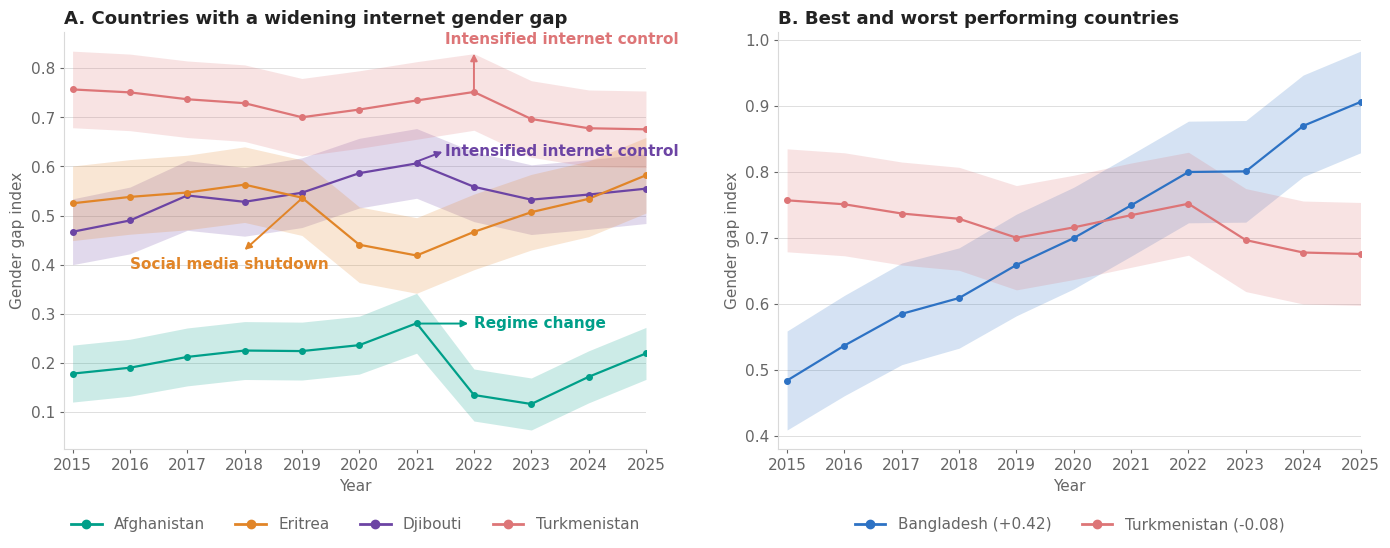

best  Bangladesh     +0.422  (0.484 -> 0.906)
worst Turkmenistan   -0.081  (0.757 -> 0.676)


In [9]:
gains = sum_i.loc[wide_i[YEARS[-1]].notna() & wide_i[TREND_START].notna(), 'total_gain']
worst, best = gains.idxmin(), gains.idxmax()
# The worst keeps the hue it has in panel A; the best takes a hue panel A does not use, so no
# reader carries an identity across the two panels that isn't there.
best_worst_colours = {best: params.colors['blue'], worst: case_colours['TKM']}

fig, axes = plt.subplots(1, 2, figsize=plot.figsize('wide'))

# -------- Panel A: widening --------
ax = axes[0]
trend_lines(ax, wide_i, err_i, sum_i, CASE_STUDIES, colours=case_colours, label=False,
            years=YEARS)
annotate_events(ax, case_colours)
plot.tidy(ax, title='A. Countries with a widening internet gender gap',
          xlabel='Year', ylabel='Gender gap index', grid='y')
year_axis(ax, YEARS)
ax.legend(handles=[plt.Line2D([], [], color=case_colours[c], linewidth=2, marker='o',
                              label=sum_i.loc[c, 'country']) for c in CASE_STUDIES],
          frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED,
          loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=4)

# -------- Panel B: best and worst --------
ax = axes[1]
trend_lines(ax, wide_i, err_i, sum_i, [best, worst], colours=best_worst_colours, label=False,
            years=YEARS)
plot.tidy(ax, title='B. Best and worst performing countries',
          xlabel='Year', ylabel='Gender gap index', grid='y')
year_axis(ax, YEARS)
ax.legend(handles=[plt.Line2D([], [], color=best_worst_colours[c], linewidth=2, marker='o',
                              label=f'{sum_i.loc[c, "country"]} ({sum_i.loc[c, "total_gain"]:+.2f})')
                   for c in (best, worst)],
          frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED,
          loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)

fig.tight_layout()
plot.save(fig, NOTEBOOK, '05_widen_best_worst')
plt.show()

print(f'best  {sum_i.loc[best, "country"]:<14} {gains[best]:+.3f}  '
      f'({wide_i.loc[best, TREND_START]:.3f} -> {wide_i.loc[best, YEARS[-1]]:.3f})')
print(f'worst {sum_i.loc[worst, "country"]:<14} {gains[worst]:+.3f}  '
      f'({wide_i.loc[worst, TREND_START]:.3f} -> {wide_i.loc[worst, YEARS[-1]]:.3f})')

### How far the ribbons carry

`predicted_error` is the model's published standard error on the prediction, so the band is a
statement about fit, not about the event annotations. Panel B's two countries separate by far more
than their bands; panel A's four do not all separate from each other. The table below is the check —
where the bands of two case-study countries overlap in a given year, the figure shows an ordering the
uncertainty does not support.

In [10]:
overlap = []
for y in YEARS:
    lo = wide_i.loc[CASE_STUDIES, y] - err_i.loc[CASE_STUDIES, y]
    hi = wide_i.loc[CASE_STUDIES, y] + err_i.loc[CASE_STUDIES, y]
    for a, b in [(i, j) for k, i in enumerate(CASE_STUDIES) for j in CASE_STUDIES[k + 1:]]:
        if lo[a] <= hi[b] and lo[b] <= hi[a]:
            overlap.append({'year': y, 'pair': f'{a}-{b}',
                            'gap': round(abs(wide_i.loc[a, y] - wide_i.loc[b, y]), 3)})

overlap = pd.DataFrame(overlap)
mean_err = err_i.loc[CASE_STUDIES, YEARS].mean(axis=1).round(3)
print(f'mean predicted_error over the window: '
      + ', '.join(f'{sum_i.loc[c, "country"]} {mean_err[c]}' for c in CASE_STUDIES))
print(f'\n{len(overlap)} of {len(YEARS) * 6} country-pair-years have overlapping bands')
overlap.pivot_table(index='pair', columns='year', values='gap') if len(overlap) else 'none overlap'

mean predicted_error over the window: Afghanistan 0.057, Eritrea 0.077, Djibouti 0.07, Turkmenistan 0.078

16 of 66 country-pair-years have overlapping bands


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pair,,,,,,,,,,,
DJI-TKM,NaN,NaN,NaN,NaN,NaN,0.130,0.128,NaN,NaN,0.135,0.121
ERI-DJI,0.058,0.048,0.006,0.035,0.01,0.146,NaN,0.092,0.025,0.009,0.027
ERI-TKM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.144,0.094


## 6. Mobile

The same figures on `mobile_fm_ratio`. The closing threshold is the `.qmd`'s `0.2` rather than
`0.3` — the mobile gap is narrower to start with, so the same cut would select almost nothing.

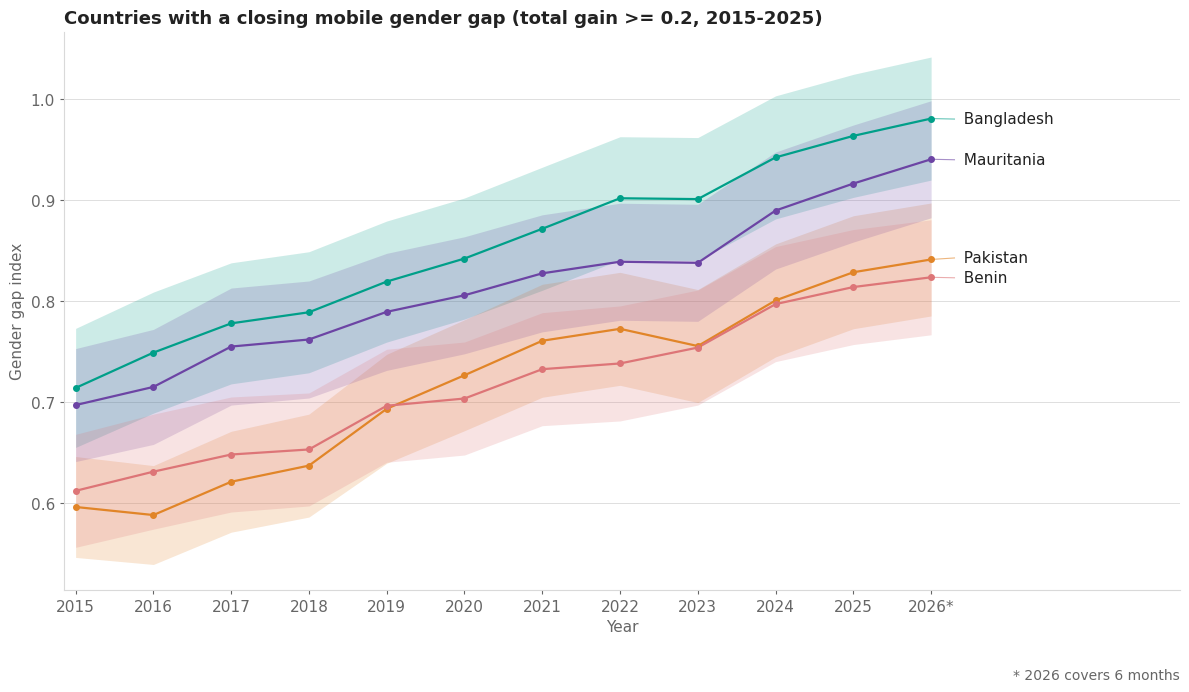

closing: 4 countries, 4 labelled



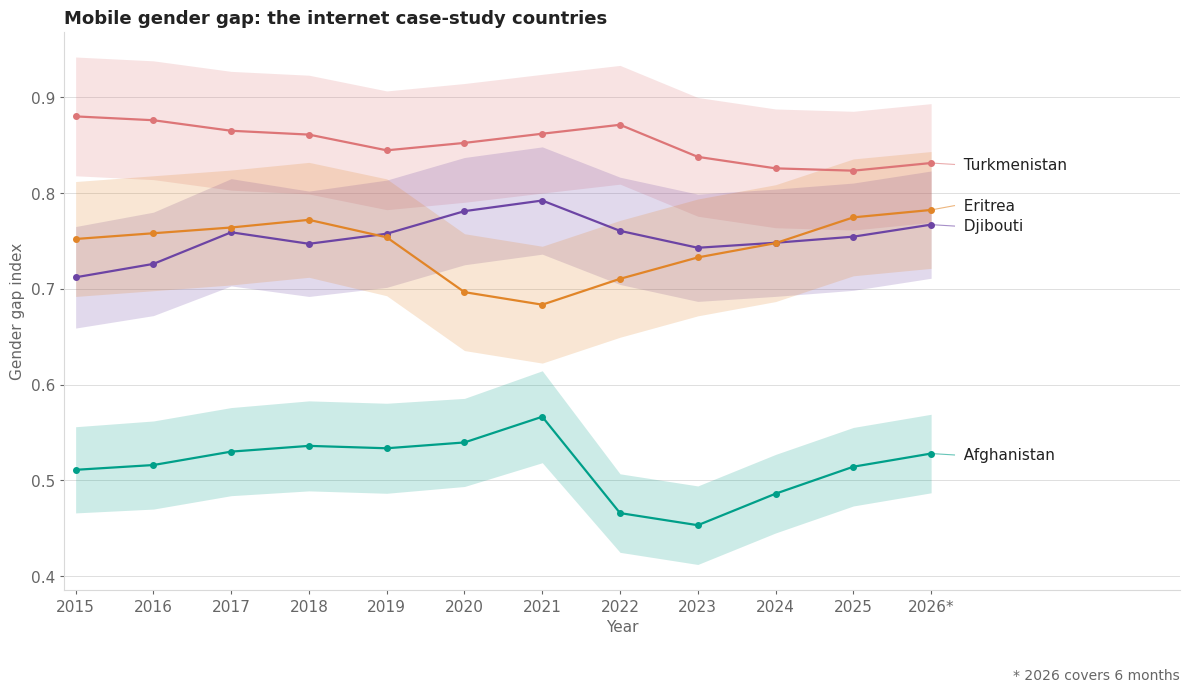

case_studies: 4 countries, 4 labelled



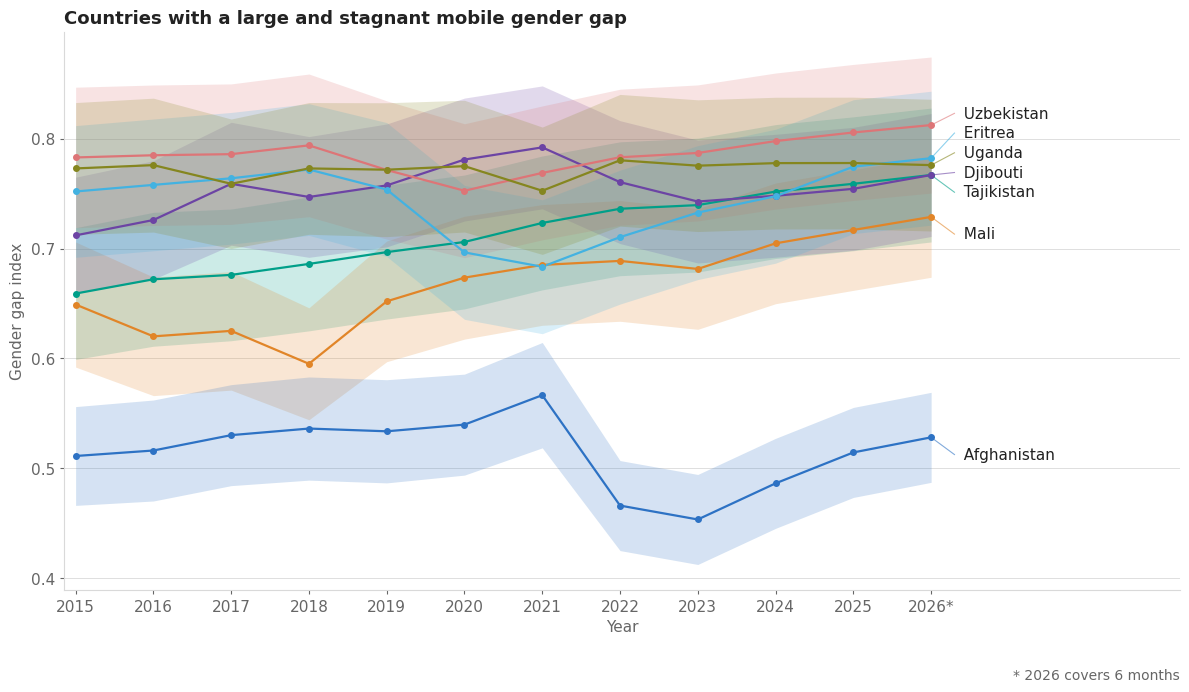

stagnant: 7 countries, 7 labelled



,country,total_gain,mean_pred
gid_0,,,
AFG,Afghanistan,0.003,0.514
ERI,Eritrea,0.023,0.740
DJI,Djibouti,0.042,0.753
TKM,Turkmenistan,-0.057,0.854


In [11]:
mobile_figs = [
    ('closing',      sum_m.index[sum_m['total_gain'] >= 0.2].tolist(),
     f'Countries with a closing mobile gender gap (total gain >= 0.2, {TREND_START}-{TREND_END})'),
    ('case_studies', CASE_STUDIES,
     'Mobile gender gap: the internet case-study countries'),
    ('stagnant',     stagnant(sum_m),
     'Countries with a large and stagnant mobile gender gap'),
]

for name, isos, title in mobile_figs:
    fig, ax = plt.subplots(figsize=plot.figsize('full'))
    colours = case_colours if name == 'case_studies' else None
    focus = trend_lines(ax, wide_m, err_m, sum_m, isos, colours=colours,
                        ribbon=len([c for c in isos if c in wide_m.index]) <= 8)
    plot.tidy(ax, title=title, xlabel='Year', ylabel='Gender gap index', grid='y')
    year_axis(ax, YEARS, gutter=3.2)
    fig.tight_layout()
    plot.save(fig, NOTEBOOK, f'06_mobile_{name}')
    plt.show()
    print(f'{name}: {len([c for c in isos if c in wide_m.index])} countries, {len(focus)} labelled\n')

sum_m.loc[[c for c in CASE_STUDIES if c in sum_m.index],
          ['country', 'total_gain', 'mean_pred']].round(3)

## 7. What the Facebook inputs did in the case-study countries

The case-study series are model output, and the models carry no country-specific term: a country's
predicted path moves only when its covariates move. For these four the Facebook audience counts are
the covariates that move, so this is where the shape in §2 comes from.

`fb_all` is the monthly active audience; `fb_age_18_plus_ratio` is the female-to-male ratio of the
18+ audience, which is the term the GGI model actually reads.

**The `.qmd` plotted Türkiye here and labelled it Turkmenistan** (`trend.qmd:517`, `iso3 == "TUR"`).
Both are drawn below so the substitution is visible: TUR is not a case-study country and its
Facebook series looks nothing like TKM's.

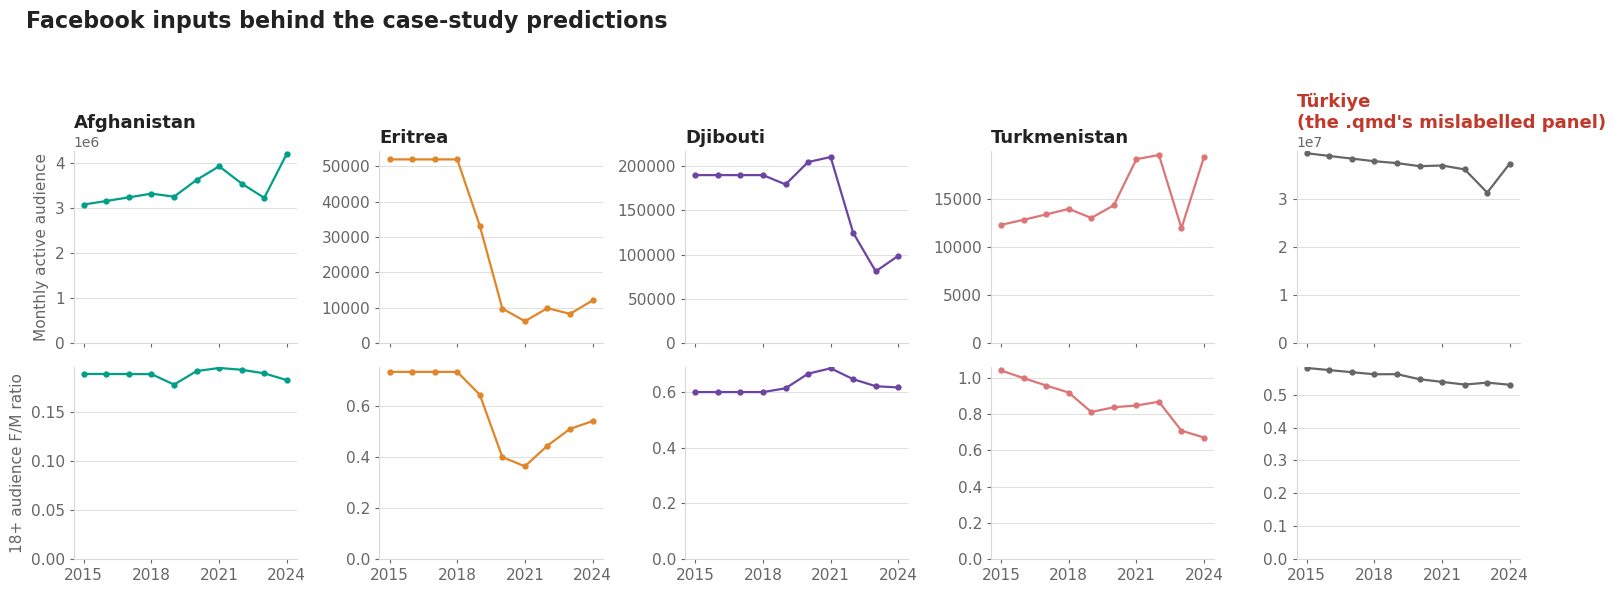

iso3,AFG,DJI,ERI,TKM,TUR
year,,,,,
2015,0.189,0.600,0.733,1.040,0.581
2016,0.189,0.600,0.733,0.998,0.575
2017,0.189,0.600,0.733,0.957,0.568
2018,0.189,0.600,0.733,0.918,0.562
2019,0.178,0.613,0.644,0.811,0.563
2020,0.192,0.666,0.399,0.837,0.547
2021,0.195,0.685,0.363,0.847,0.539
2022,0.193,0.646,0.444,0.868,0.531
2023,0.190,0.621,0.510,0.708,0.537


In [12]:
fb = pd.read_csv(params.EXTERNAL / 'pipeline/pre_pipeline_result/fb_national.csv')
fb_countries = CASE_STUDIES + ['TUR']     # TUR is the .qmd's mislabelled panel, shown for contrast

fb_annual = (fb[fb['iso3'].isin(fb_countries)]
             .groupby(['iso3', 'year'], as_index=False)
             .agg(mau=('fb_all', 'mean'), ratio_18_plus=('fb_age_18_plus_ratio', 'mean')))
fb_annual = fb_annual[fb_annual['year'].between(TREND_START, TREND_END)]

fig, axes = plt.subplots(2, len(fb_countries), figsize=plot.figsize(nrow=2, ncol=len(fb_countries)), sharex=True)
for col, iso in enumerate(fb_countries):
    block = fb_annual[fb_annual['iso3'] == iso].sort_values('year')
    colour = case_colours.get(iso, MUTED)
    name = utils.get_country_name_from_iso3(iso)
    for row, (measure, label) in enumerate([('mau', 'Monthly active audience'),
                                            ('ratio_18_plus', '18+ audience F/M ratio')]):
        ax = axes[row, col]
        ax.plot(block['year'], block[measure], color=colour, linewidth=1.6, marker='o',
                markersize=3.5)
        ax.set_ylim(bottom=0)
        plot.tidy(ax, title=f'{name}' if row == 0 else None, grid='y')
        if col == 0:
            ax.set_ylabel(label, fontsize=STYLE['tick_fs'], color=MUTED)
        if row == 1:
            ax.set_xticks(range(TREND_START, TREND_END + 1, 3))

axes[0, len(fb_countries) - 1].set_title(
    f'{utils.get_country_name_from_iso3("TUR")}\n(the .qmd\'s mislabelled panel)',
    fontsize=STYLE['label_fs'], color=FLAG, fontweight='bold', loc='left')
plot.suptitle(fig, 'Facebook inputs behind the case-study predictions')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plot.save(fig, NOTEBOOK, '07_fb_inputs_case_studies')
plt.show()

fb_annual.pivot_table(index='year', columns='iso3', values='ratio_18_plus').round(3)

## 8. National against subnational-aggregated predictions

Salvaged from the archived notebook, and rebuilt: the original merged a local random-forest refit
against the subnational file and failed on a missing key. This compares the **published** national
prediction against `subnational_aggregated_to_national.csv` — the subnational model's output summed
back up to the country — on the same annual grain, for all six outcomes.

They are two models of the same quantity, not a prediction and a truth, so the diagonal is the
question: where the two disagree, the country's national and subnational estimates are telling
different stories and neither is a check on the other.

In [13]:
subnat = pd.read_csv(params.dropbox_data_path.parent / 'files/subnational_aggregated_to_national.csv')

paired = (annual[['gid_0', 'outcome', 'year', 'pred', 'country', 'region']]
          .merge(subnat, on=['gid_0', 'outcome', 'year'], how='inner')
          .dropna(subset=['pred', 'predicted_subnational']))
paired['diff'] = paired['pred'] - paired['predicted_subnational']

report = (paired.groupby('outcome')
          .apply(lambda g: pd.Series({
              'n': len(g),
              'countries': g['gid_0'].nunique(),
              'mean_diff': g['diff'].mean(),
              'mean_abs_diff': g['diff'].abs().mean(),
              'p95_abs_diff': g['diff'].abs().quantile(0.95),
              'corr': g['pred'].corr(g['predicted_subnational']),
          }), include_groups=False).round(3))
report.to_csv(params.table_dir(NOTEBOOK) / f'national_vs_subnational_{STAMP}.csv')
report

,n,countries,mean_diff,mean_abs_diff,p95_abs_diff,corr
outcome,,,,,,
internet_fm_ratio,1288.0,118.0,0.036,0.069,0.191,0.950
internet_men,1288.0,118.0,-0.046,0.086,0.193,0.933
internet_women,1288.0,118.0,-0.004,0.089,0.211,0.932
mobile_fm_ratio,1288.0,118.0,0.026,0.038,0.132,0.945
mobile_men,1288.0,118.0,-0.025,0.060,0.150,0.809
mobile_women,1288.0,118.0,-0.015,0.068,0.158,0.927


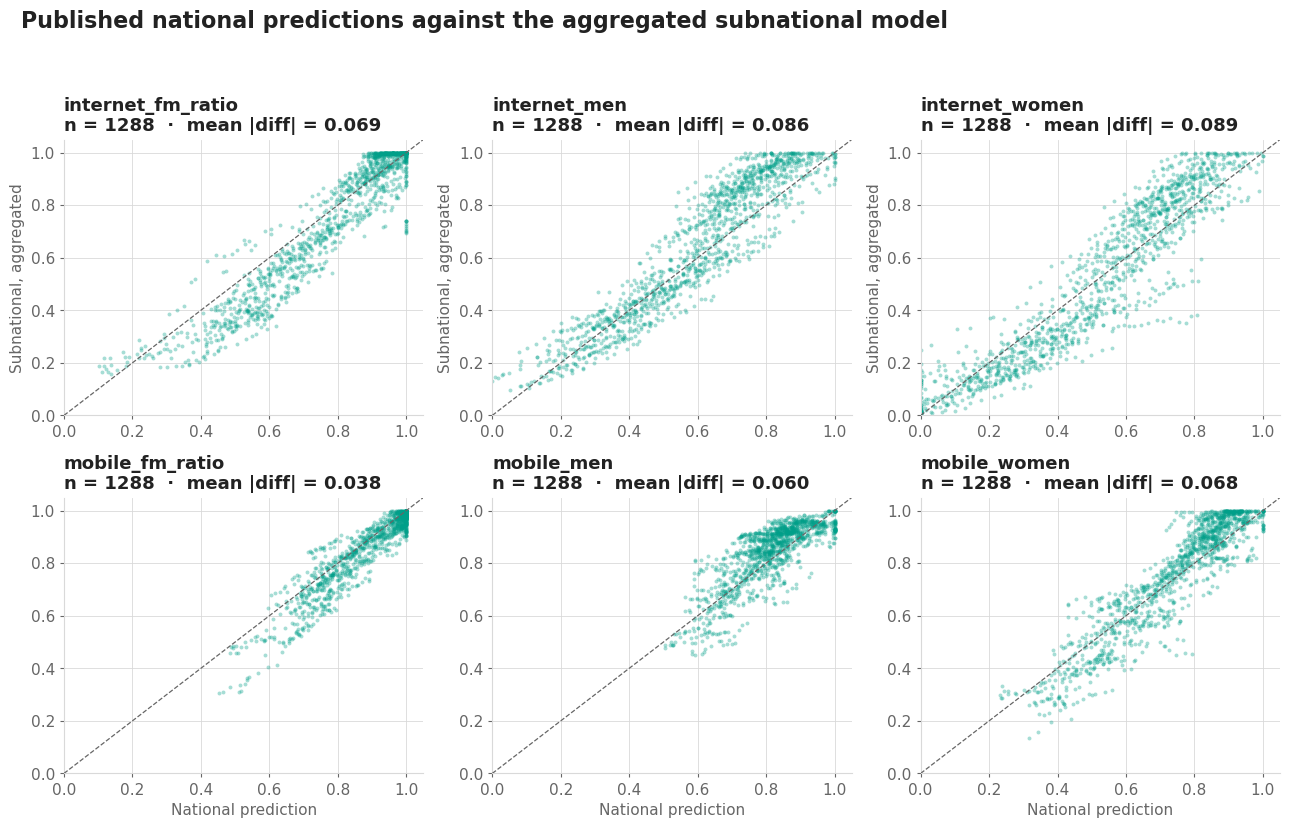

,country,outcome,year,pred,predicted_subnational,diff
824,Belarus,internet_women,2025,0.807,0.382,0.425
822,Belarus,internet_women,2023,0.775,0.352,0.424
823,Belarus,internet_women,2024,0.790,0.379,0.411
821,Belarus,internet_women,2022,0.755,0.356,0.399
820,Belarus,internet_women,2021,0.728,0.371,0.357
819,Belarus,internet_women,2020,0.709,0.360,0.350
2837,Equatorial Guinea,mobile_women,2025,0.794,0.455,0.339
818,Belarus,internet_women,2019,0.690,0.361,0.328
2836,Equatorial Guinea,mobile_women,2024,0.772,0.457,0.315
817,Belarus,internet_women,2018,0.664,0.351,0.313


In [14]:
outcomes = sorted(paired['outcome'].unique())
fig, axes = plt.subplots(2, 3, figsize=plot.figsize('tall'))
axes = axes.ravel()

for ax, outcome in zip(axes, outcomes):
    block = paired[paired['outcome'] == outcome]
    ax.scatter(block['pred'], block['predicted_subnational'], s=8, alpha=0.35,
               color=PALETTE[0], linewidths=0)
    lims = [0, 1.05]
    ax.plot(lims, lims, color=MUTED, linewidth=0.9, linestyle='--', zorder=3)
    ax.set_xlim(lims); ax.set_ylim(lims)
    mad = block['diff'].abs().mean()
    plot.tidy(ax, title=f'{outcome}\nn = {len(block)}  ·  mean |diff| = {mad:.3f}', grid='both')

for ax in axes[:3]:
    ax.set_ylabel('Subnational, aggregated', fontsize=STYLE['tick_fs'], color=MUTED)
for ax in axes[3:]:
    ax.set_xlabel('National prediction', fontsize=STYLE['tick_fs'], color=MUTED)

plot.suptitle(fig, 'Published national predictions against the aggregated subnational model')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plot.save(fig, NOTEBOOK, '08_national_vs_subnational')
plt.show()

worst_rows = paired.reindex(paired['diff'].abs().sort_values(ascending=False).index)
worst_rows[['country', 'outcome', 'year', 'pred', 'predicted_subnational', 'diff']].head(10).round(3)

## 9. What the ground truth actually covers

Also salvaged. The trend figures are model output for 214 countries; the surveys behind the models
are not. This is what the fitting panel is built from, by source and year — the denominator for
every claim above.

`itu` rows are administrative reporting, not a household survey, and the production model keeps them
(`combined_with_CIS`, D12); DHS and MICS are surveys. The distinction matters for reading the trend:
a country whose only ground truth is ITU has never had its gender gap measured by a survey.

In [15]:
truth = pd.read_csv(params.RAW / 'new_groundtruth_national_data.csv')
truth = truth[truth['survey_year'] >= TREND_START]
truth['source_agg'] = np.select(
    [truth['source'].eq('itu'), truth['source'].str.contains('dhs'), truth['source'].str.contains('mics')],
    ['itu', 'dhs', 'mics'], default='other')

wide_truth = truth.pivot_table(index=['gid_0', 'source_agg', 'survey_year'],
                               columns='outcome', values='observed').reset_index()

coverage = pd.DataFrame({
    ind: wide_truth.groupby('source_agg')[f'{ind}_fm_ratio'].apply(lambda s: s.notna().sum())
    for ind in INDICATORS
})
coverage['country_years'] = wide_truth.groupby('source_agg').size()
coverage['countries'] = wide_truth.groupby('source_agg')['gid_0'].nunique()
coverage.to_csv(params.table_dir(NOTEBOOK) / f'groundtruth_coverage_{STAMP}.csv')

survey_only = set(wide_truth.loc[wide_truth['source_agg'] != 'itu', 'gid_0'])
predicted = set(wide_i.index)
print(f'{len(predicted)} countries carry an internet prediction')
print(f'{len(survey_only & predicted)} of them have at least one DHS/MICS observation since {TREND_START}')
print(f'{len(predicted - survey_only)} have none\n')
coverage

213 countries carry an internet prediction
59 of them have at least one DHS/MICS observation since 2015
154 have none



,internet,mobile,country_years,countries
source_agg,,,,
dhs,41,42,42,38
itu,124,89,146,126
mics,31,31,31,31


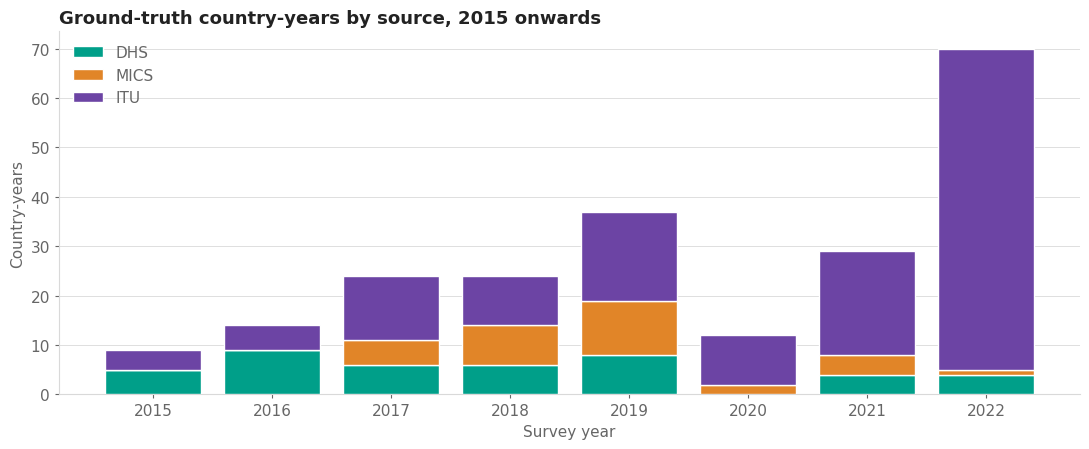

source_agg,dhs,mics,itu,other
survey_year,,,,
2015,5,0,4,0
2016,9,0,5,0
2017,6,5,13,0
2018,6,8,10,0
2019,8,11,18,0
2020,0,2,10,0
2021,4,4,21,0
2022,4,1,65,0


In [16]:
by_year = (wide_truth.groupby(['survey_year', 'source_agg']).size()
           .unstack(fill_value=0).reindex(columns=['dhs', 'mics', 'itu', 'other'], fill_value=0))

fig, ax = plt.subplots(figsize=plot.figsize('wide'))
bottom = np.zeros(len(by_year))
for i, source in enumerate(by_year.columns):
    if by_year[source].sum() == 0:
        continue
    ax.bar(by_year.index, by_year[source], bottom=bottom, color=PALETTE[i], edgecolor=plot.EDGE,
           linewidth=1, label=source.upper(), zorder=3)
    bottom += by_year[source].values

plot.tidy(ax, title=f'Ground-truth country-years by source, {TREND_START} onwards',
          xlabel='Survey year', ylabel='Country-years', grid='y')
ax.set_xticks(by_year.index)
ax.legend(frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED)
fig.tight_layout()
plot.save(fig, NOTEBOOK, '09_groundtruth_by_source')
plt.show()

by_year

## Notes

**The measure.** Everything above is `{ind}_fm_ratio` — the GGI predicted by its own model, clipped
to `[0, 1]` upstream. It is not derived from the predicted female and male levels, so it does not
have to agree with them, and where it disagrees by more than 0.07 the country-year is dropped from
06's decomposition (D43). Nothing is dropped here: this notebook is the direct measure on its own
terms, and the comparison between the two measures is 05's job.

**The ceiling.** The clip at 1.0 flattens every country that reaches parity, so `total_gain` is
bounded above by `1 - pred[2015]`: a country starting at 0.9 cannot post a gain above 0.1 and can
never enter §1's set. §1 therefore selects countries that started **low** and moved, which is not the
same as the countries that improved most. §4's `mean_pred < 0.8` is the mirror of this.

**Complete years only.** The window ends at the last year with twelve months of data; a year
still filling up is dropped before anything is plotted (D54). This matters more than a footnote
would fix: the Facebook audience series has seasonality, so a mean over part of a calendar year is
not comparable to a mean over all of it, and the incomparable point would sit at the end of the
trend where every gain and every classification is measured.

**Figures write to** `outputs/fig/09_direct_ggi_trend_figures/`; the R originals in
`outputs/fig/08_prediction_and_convergence/widen_best_worst.png` and the `trend_analysis_PAA`
folder are left untouched for comparison.